In [ ]:
# this notebook explores the supposed 'eta anomaly' where in both a high-res 1-face model, a global coarse model,
# and even a very old 1-tile model
# predicted eta RMSE becomes identical to persistence, U and V errors spike, and typical tracer advection seems to 
# pause during the temporal range of roughly 11/9 and 11/11 2012.
# This indicates that forcing variability halts during this time range and is so likely a defect of the underlying data. This was copied into coarse caches and the high res boundary rechunk cache. 
# At least for the surface, this indicates that surface fields move ‘physically’ in direct consequence of the forcings – flat forcings = little surface response. T
# his exposes a model weakness: collapse to forcing rather than physical evolution of fields.
# Next step is to explore how this propagates into depth
# visual inspection 


import matplotlib.pyplot as plt
import xarray as xr
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [ ]:
# below is the exploration of depth propagation w/ videos as that's the easiest way to visualize this

In [ ]:
face_1_ckpt17 = xr.open_zarr('/orcd/scratch/seedfund/001/llc_emulator/inference/1face//epoch17-ema/predictions.zarr').isel(time=slice(588,744),lon=slice(2880,3600),lat=slice(720,1440))


In [38]:
d0=0
d1=30

In [39]:
th0 = face_1_ckpt17[f'Theta_{d0}'].load()
th1 = face_1_ckpt17[f'Theta_{d1}'].load()

u0 = face_1_ckpt17[f'U_{d0}'].load()
u1 = face_1_ckpt17[f'U_{d1}'].load()


In [34]:


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ims = []
for ax, th, d in zip(axes, [th0, th1], [d0, d1]):
    im = ax.imshow(th.isel(time=0), origin='lower', cmap='RdYlBu_r',
                   vmin=float(th.min()), vmax=float(th.max()))
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(f'Theta_{d}')
    ims.append(im)
title = fig.suptitle('hour 0')

def update(t):
    for im, th in zip(ims, [th0, th1]):
        im.set_data(th.isel(time=t))
    title.set_text(f'hour {t}')
    return ims

anim = FuncAnimation(fig, update, frames=th0.sizes['time'], interval=1000/12)  # 12 fps
plt.close(fig)
HTML(anim.to_jshtml(fps=12))

Animation size has reached 21285649 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ims = []
for ax, th, d in zip(axes, [u0, u1], [d0, d1]):
    im = ax.imshow(th.isel(time=0), origin='lower', cmap='RdYlBu_r',
                   vmin=float(th.min()), vmax=float(th.max()))
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(f'Theta_{d}')
    ims.append(im)
title = fig.suptitle('hour 0')

def update(t):
    for im, th in zip(ims, [u0, u1]):
        im.set_data(th.isel(time=t))
    title.set_text(f'hour {t}')
    return ims

anim = FuncAnimation(fig, update, frames=u0.sizes['time'], interval=1000/6)  # 12 fps
plt.close(fig)
HTML(anim.to_jshtml(fps=6))

Animation size has reached 21225722 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


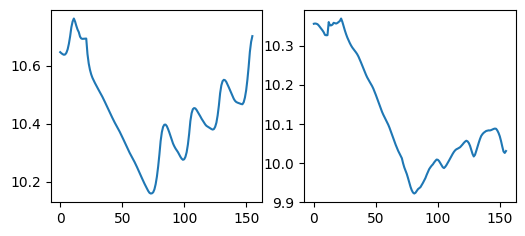

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
axes[0].plot(th0.mean(dim=("lat","lon")))
axes[1].plot(th1.mean(dim=("lat","lon")))

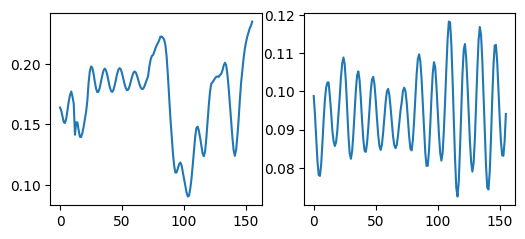

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))
axes[0].plot(u0.mean(dim=("lat","lon")))
axes[1].plot(u1.mean(dim=("lat","lon")))

In [ ]:
# below is 1 deg check:-

In [2]:
one_deg = xr.open_zarr('/orcd/scratch/seedfund/001/llc_emulator/coarse/LLC4320_samudra_1deg.zarr')

In [3]:
one_deg.oceTAUY

<xarray.DataArray 'oceTAUY' (time: 10311, y: 180, x: 360)> Size: 3GB
dask.array<open_dataset-oceTAUY, shape=(10311, 180, 360), dtype=float32, chunksize=(1, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 82kB 2011-09-13 ... 2012-11-15T14:00:00
Dimensions without coordinates: y, x

In [4]:
slices = [(0,1000),(1000,2000),(2000,3000),(3000,4000),(4000,5000),(5000,6000),(6000,7000),(7000,8000),(8000,9000),(9000,10311)]
for r in slices:
    print(r[0])

0
1000
2000
3000
4000
5000
6000
7000
8000
9000


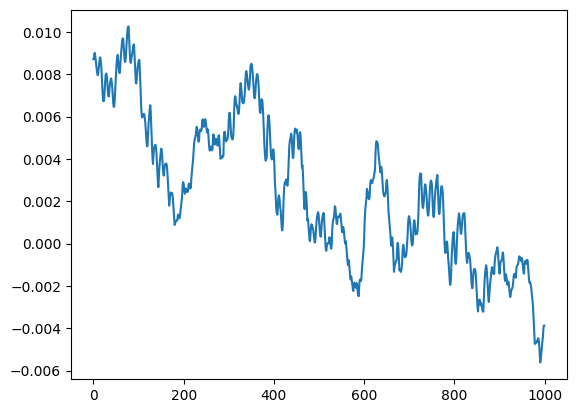

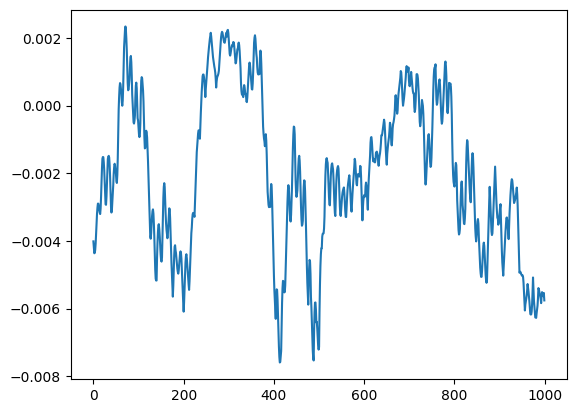

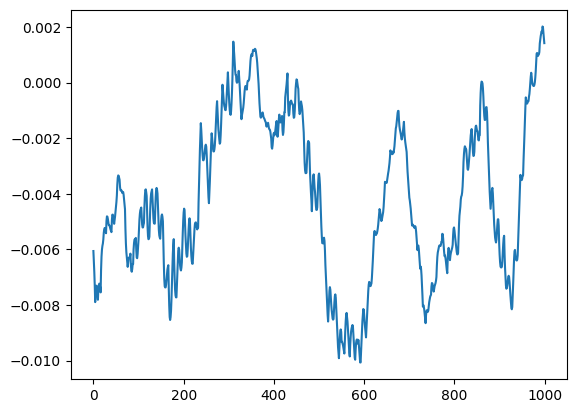

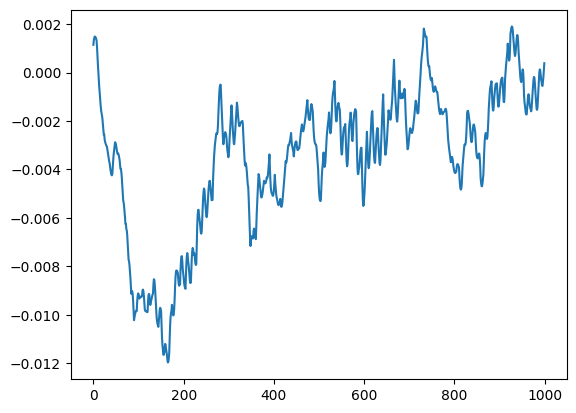

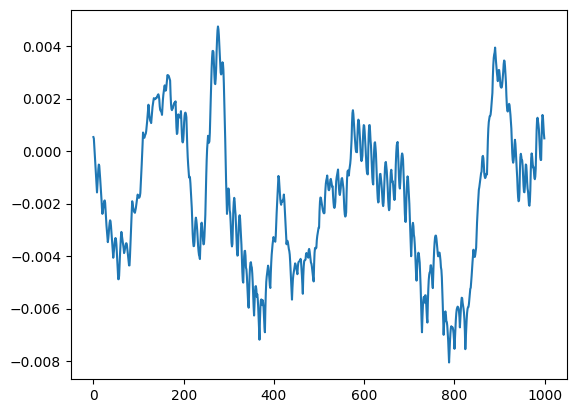

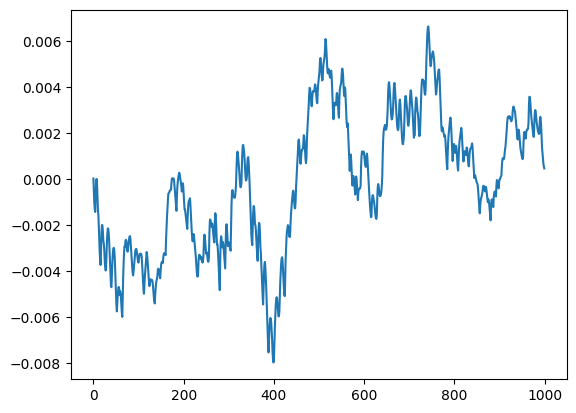

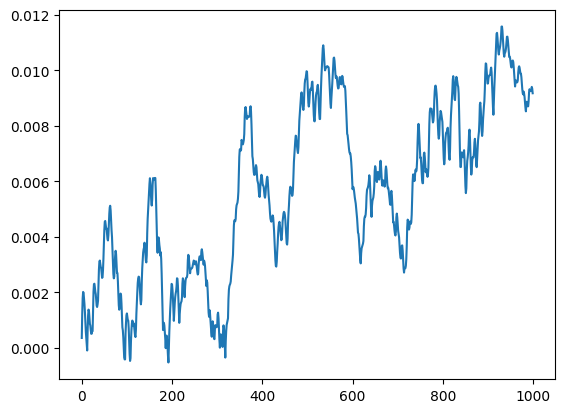

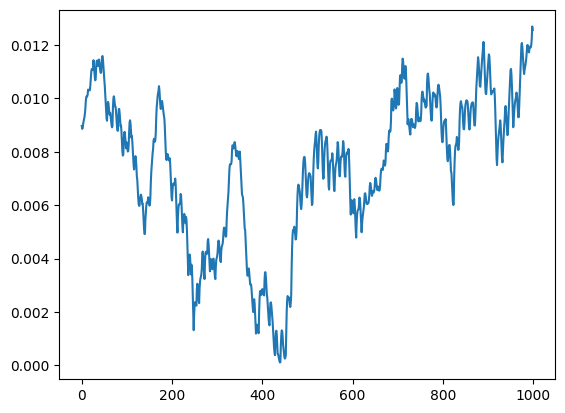

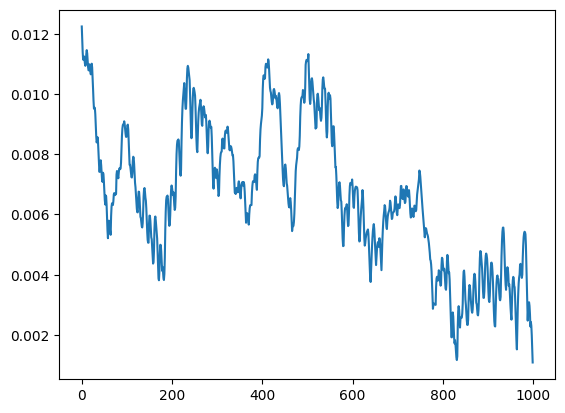

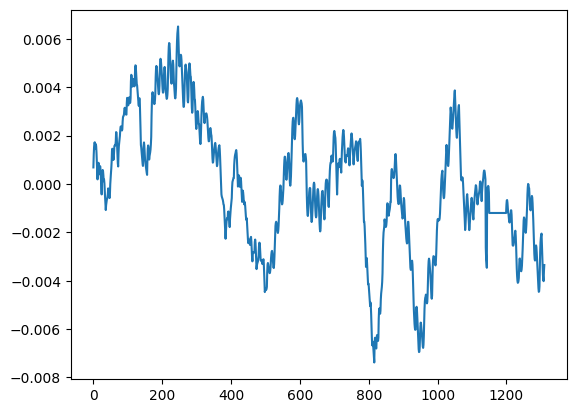

In [5]:
for r in slices:
    plt.plot(one_deg.oceTAUY.isel(time=slice(r[0],r[1])).mean(dim=("x","y")))
    plt.show()

In [ ]:
# below is the constant forcing anomaly:

In [47]:
llc = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320')

/tmp/ipykernel_3366670/3049893463.py:1: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  llc = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320')


In [48]:
llc_boundary_cache = xr.open_zarr('/orcd/data/abodner/002/cody/LLC_boundary_rechunk/LLC4320_2d_720.zarr')

In [53]:
sel = llc.isel(time=slice(10311-(24*7),10311-(24*3)),face=4)
taux = sel.oceTAUX
tauy = sel.oceTAUY
eta = sel.Eta
qnet = sel.oceQnet
U = sel.isel(k=0).U
V = sel.isel(k=0).V
theta = sel.isel(k=0).Theta
salt = sel.isel(k=0).Salt
fresh_flux = sel.oceFWflx
salt_flux = sel.oceSflux

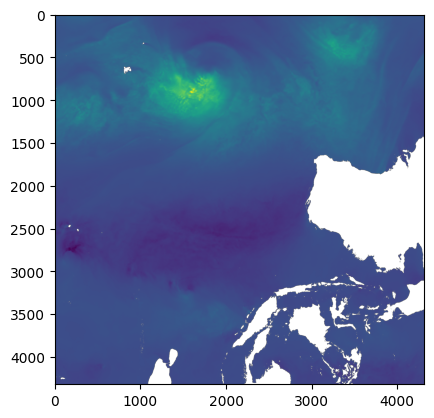

In [54]:
plt.imshow(taux.isel(time=40))

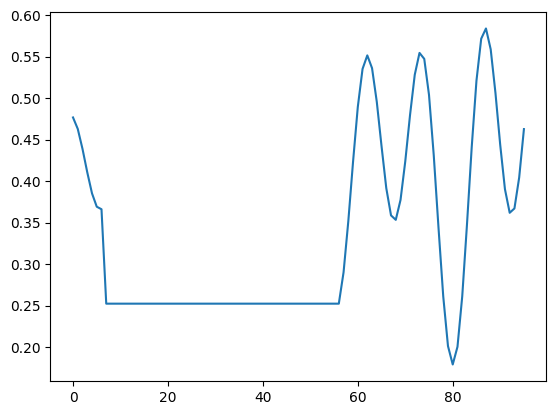

In [55]:
plt.plot(eta.mean(dim=("j","i")))

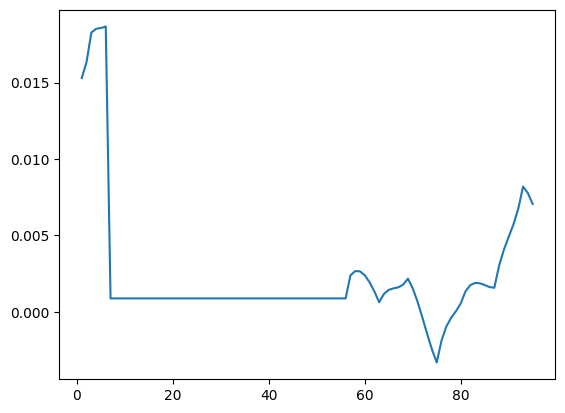

In [ ]:
plt.plot(tauy.mean(dim=("j_g","i")))

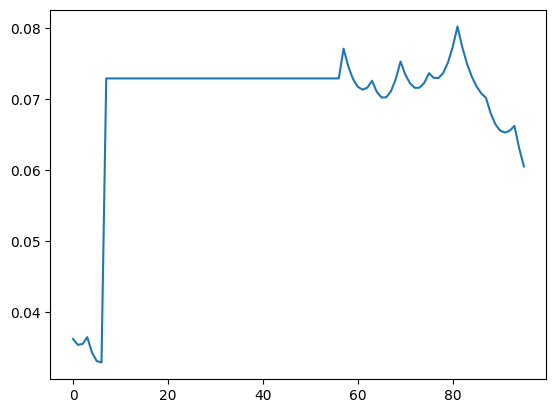

In [ ]:
plt.plot(taux.mean(dim=("j","i_g")))


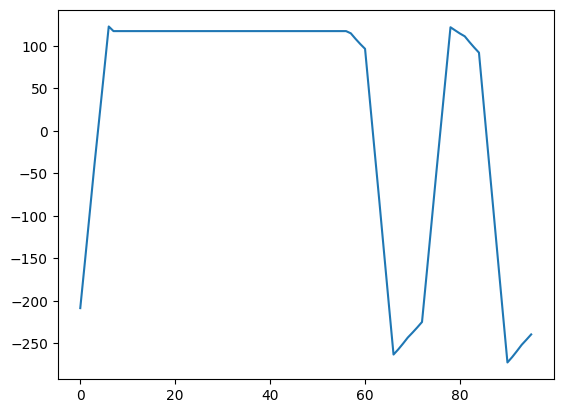

In [ ]:
plt.plot(qnet.mean(dim=("j","i")))



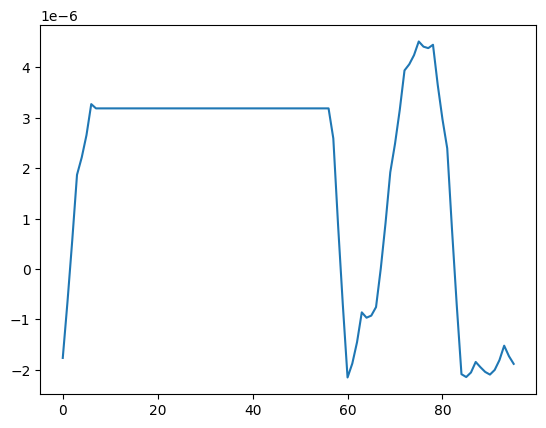

In [ ]:
plt.plot(fresh_flux.mean(dim=("j","i")))



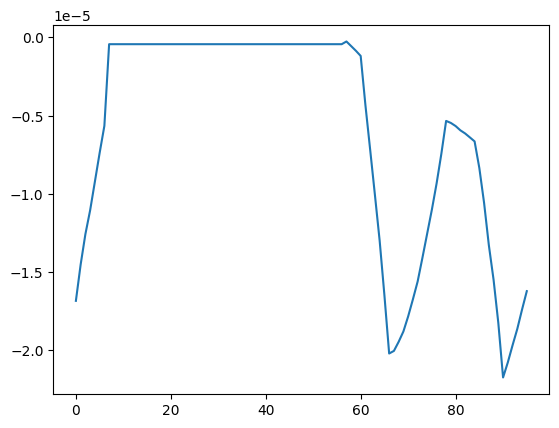

In [ ]:
plt.plot(salt_flux.mean(dim=("j","i")))


In [33]:
sel = llc_boundary_cache.isel(time=slice(10311-(24*7),10311-(24*3)),face=1)
taux = sel.oceTAUX
tauy = sel.oceTAUY
eta = sel.Eta
qnet = sel.oceQnet
fresh_flux = sel.oceFWflx

In [39]:
llc_boundary_cache

<xarray.Dataset> Size: 50TB
Dimensions:   (time: 10311, face: 13, j: 4320, i: 4320, i_g: 4320, j_g: 4320,
               variable: 5)
Coordinates:
  * time      (time) datetime64[ns] 82kB 2011-09-13 ... 2012-11-15T14:00:00
Dimensions without coordinates: face, j, i, i_g, j_g, variable
Data variables:
    Eta       (time, face, j, i) float32 10TB dask.array<chunksize=(1, 1, 720, 720), meta=np.ndarray>
    hFacC_2d  (face, j, i) float32 970MB dask.array<chunksize=(1, 720, 720), meta=np.ndarray>
    oceFWflx  (time, face, j, i) float32 10TB dask.array<chunksize=(1, 1, 720, 720), meta=np.ndarray>
    oceQnet   (time, face, j, i) float32 10TB dask.array<chunksize=(1, 1, 720, 720), meta=np.ndarray>
    oceTAUX   (time, face, j, i_g) float32 10TB dask.array<chunksize=(1, 1, 720, 720), meta=np.ndarray>
    oceTAUY   (time, face, j_g, i) float32 10TB dask.array<chunksize=(1, 1, 720, 720), meta=np.ndarray>
    repaired  (time, variable) float32 206kB dask.array<chunksize=(1, 5), meta=np.ndarray>
Attributes: (12/13)
    built_by:                coarsen_llc.py
    compression:             blosc zstd level 3, byte shuffle
    description:             LLC4320 2D fields rechunked to 720x720 tiles; ra...
    fill_rule:               each bad raw pixel (outside LIMITS, infinite, Na...
    filled_time_steps_json:  {"Eta": [], "oceTAUX": [0, 288, 384, 408, 552, 5...
    plan:                    docs/10-15-26-coarsen_LLC_plan.md
    ...                      ...
    repaired_hours_json:     [0, 104, 142, 143, 288, 289, 290, 291, 292, 312,...
    repairs_log:             /orcd/scratch/seedfund/001/llc_emulator/coarse/r...
    source_path:             /orcd/data/abodner/003/LLC4320/LLC4320
    target_grid_path:        /orcd/data/abodner/002/cody/OM4.zarr
    train_steps:             [0, 8808]
    val_steps:               [8808, 10311]

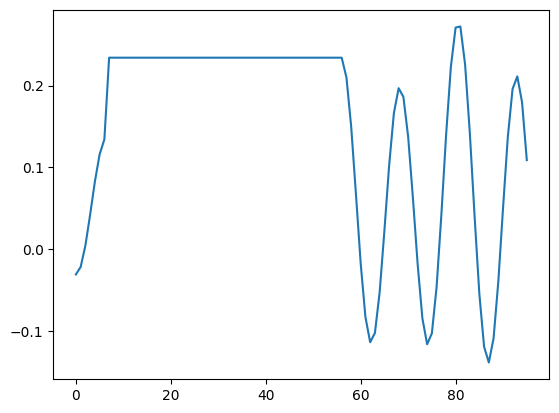

In [34]:
plt.plot(eta.mean(dim=("j","i")))


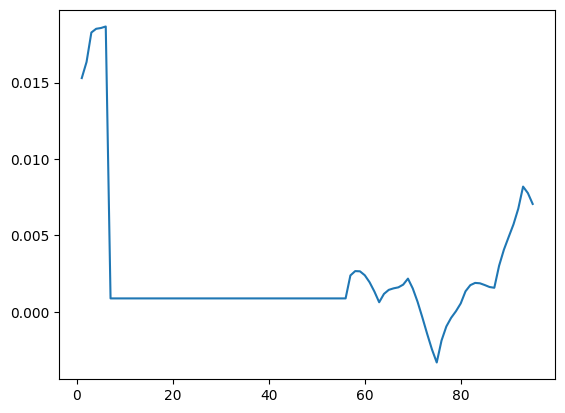

In [35]:
plt.plot(tauy.mean(dim=("j_g","i")))

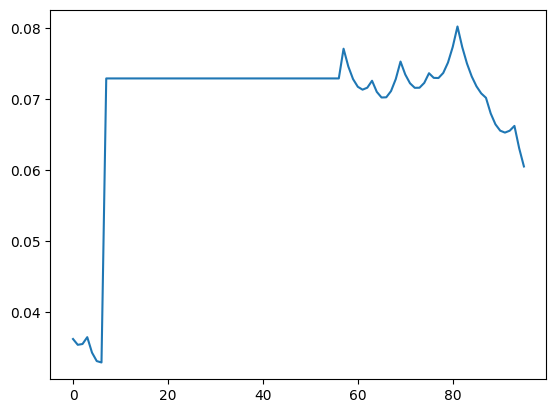

In [36]:
plt.plot(taux.mean(dim=("j","i_g")))

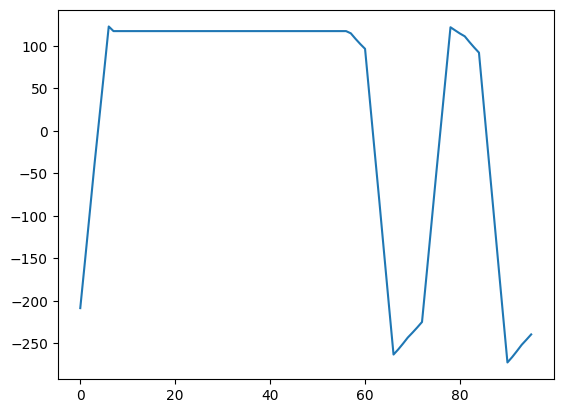

In [37]:
plt.plot(qnet.mean(dim=("j","i")))

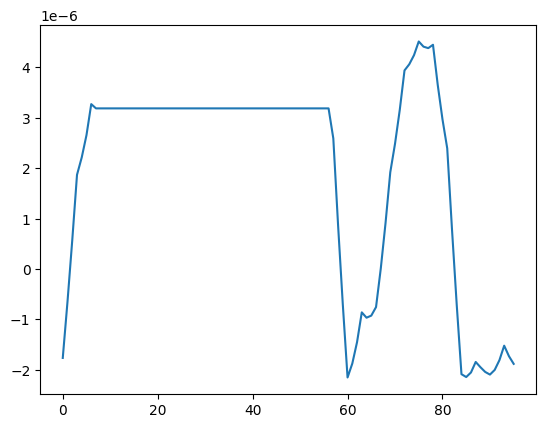

In [38]:
plt.plot(fresh_flux.mean(dim=("j","i")))